# Tugas Perpustakaan — SQLite dan Pandas
Andy Yulistiansyah - 411232057

## 1. Database perpustakaan

In [13]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

conn = sqlite3.connect('perpustakaan.db')
_ = conn.execute('PRAGMA foreign_keys = ON')

### Membuat tabel buku, anggota, dan peminjaman

In [14]:
cursor = conn.cursor()

# Hapus tabel lama supaya notebook bisa dijalankan ulang.
cursor.executescript("""
DROP TABLE IF EXISTS peminjaman;
DROP TABLE IF EXISTS anggota;
DROP TABLE IF EXISTS buku;

CREATE TABLE buku (
    id INTEGER PRIMARY KEY,
    judul TEXT NOT NULL,
    penulis TEXT NOT NULL,
    tahun INTEGER NOT NULL
);

CREATE TABLE anggota (
    id INTEGER PRIMARY KEY,
    nama TEXT NOT NULL,
    email TEXT NOT NULL
);

CREATE TABLE peminjaman (
    id INTEGER PRIMARY KEY,
    id_anggota INTEGER NOT NULL,
    id_buku INTEGER NOT NULL,
    tgl_pinjam TEXT NOT NULL,
    tgl_kembali TEXT,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku) REFERENCES buku(id)
);
""")
conn.commit()
print('Tiga tabel berhasil dibuat.')

Tiga tabel berhasil dibuat.


### 1a. Mengisi 5 buku dan 3 anggota

In [15]:
data_buku = [
    (1, 'Laskar Pelangi', 'Andrea Hirata', 2005),
    (2, 'Bumi Manusia', 'Pramoedya Ananta Toer', 1980),
    (3, 'Negeri 5 Menara', 'Ahmad Fuadi', 2009),
    (4, 'Filosofi Kopi', 'Dee Lestari', 2006),
    (5, '5 cm', 'Donny Dhirgantoro', 2005)
]

data_anggota = [
    (1, 'Rina Putri', 'rina@example.com'),
    (2, 'Budi Santoso', 'budi@example.com'),
    (3, 'Dimas Pratama', 'dimas@example.com')
]

cursor.executemany('INSERT INTO buku VALUES (?, ?, ?, ?)', data_buku)
cursor.executemany('INSERT INTO anggota VALUES (?, ?, ?)', data_anggota)
conn.commit()

print('Data buku:')
display(pd.read_sql_query('SELECT * FROM buku', conn))
print('Data anggota:')
display(pd.read_sql_query('SELECT * FROM anggota', conn))

Data buku:


,id,judul,penulis,tahun
0,1,Laskar Pelangi,Andrea Hirata,2005
1,2,Bumi Manusia,Pramoedya Ananta Toer,1980
2,3,Negeri 5 Menara,Ahmad Fuadi,2009
3,4,Filosofi Kopi,Dee Lestari,2006
4,5,5 cm,Donny Dhirgantoro,2005


Data anggota:


,id,nama,email
0,1,Rina Putri,rina@example.com
1,2,Budi Santoso,budi@example.com
2,3,Dimas Pratama,dimas@example.com


### 1b. Memasukkan 4 transaksi peminjaman

In [16]:
data_peminjaman = [
    (1, 1, 1, '2026-11-01', '2026-11-08'),
    (2, 2, 2, '2026-11-03', '2026-11-12'),
    (3, 1, 3, '2026-11-05', None),    # belum dikembalikan
    (4, 3, 4, '2026-11-06', '2026-11-15')
]

cursor.executemany(
    'INSERT INTO peminjaman VALUES (?, ?, ?, ?, ?)',
    data_peminjaman
)
conn.commit()
display(pd.read_sql_query('SELECT * FROM peminjaman', conn))

,id,id_anggota,id_buku,tgl_pinjam,tgl_kembali
0,1,1,1,2026-11-01,2026-11-08
1,2,2,2,2026-11-03,2026-11-12
2,3,1,3,2026-11-05,None
3,4,3,4,2026-11-06,2026-11-15


### 1c. Daftar peminjaman lengkap (JOIN)

In [17]:
query_join = """
SELECT
    p.id,
    a.nama AS nama_anggota,
    b.judul AS judul_buku,
    p.tgl_pinjam,
    p.tgl_kembali
FROM peminjaman AS p
JOIN anggota AS a ON p.id_anggota = a.id
JOIN buku AS b ON p.id_buku = b.id
ORDER BY p.id;
"""

display(pd.read_sql_query(query_join, conn))

,id,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Rina Putri,Laskar Pelangi,2026-11-01,2026-11-08
1,2,Budi Santoso,Bumi Manusia,2026-11-03,2026-11-12
2,3,Rina Putri,Negeri 5 Menara,2026-11-05,None
3,4,Dimas Pratama,Filosofi Kopi,2026-11-06,2026-11-15


### 1d. Jumlah buku yang dipinjam tiap anggota (GROUP BY)

In [18]:
query_jumlah = """
SELECT
    a.nama AS nama_anggota,
    COUNT(p.id) AS jumlah_peminjaman
FROM anggota AS a
LEFT JOIN peminjaman AS p ON a.id = p.id_anggota
GROUP BY a.id, a.nama
ORDER BY a.id;
"""

df_jumlah = pd.read_sql_query(query_jumlah, conn)
display(df_jumlah)

,nama_anggota,jumlah_peminjaman
0,Rina Putri,2
1,Budi Santoso,1
2,Dimas Pratama,1


## 2. Analisis data menggunakan Pandas

### 2a. Membuat DataFrame dari hasil query SQL

In [19]:
df_pinjam = pd.read_sql_query(query_join, conn)
print('DataFrame hasil query JOIN:')
display(df_pinjam)

DataFrame hasil query JOIN:


,id,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Rina Putri,Laskar Pelangi,2026-11-01,2026-11-08
1,2,Budi Santoso,Bumi Manusia,2026-11-03,2026-11-12
2,3,Rina Putri,Negeri 5 Menara,2026-11-05,None
3,4,Dimas Pratama,Filosofi Kopi,2026-11-06,2026-11-15


### 2b. Menghitung durasi dan status peminjaman

In [20]:
df_analisis = df_pinjam.copy()

tgl_pinjam = pd.to_datetime(df_analisis['tgl_pinjam'])
tgl_kembali = pd.to_datetime(df_analisis['tgl_kembali'])

df_analisis['durasi_hari'] = (tgl_kembali - tgl_pinjam).dt.days.astype('Int64')
df_analisis['status'] = df_analisis['tgl_kembali'].apply(
    lambda x: 'Belum kembali' if pd.isna(x) else 'Sudah kembali'
)

display(df_analisis[
    ['nama_anggota', 'judul_buku', 'durasi_hari', 'status']
])

print('Total transaksi:', len(df_analisis))
print('Sudah kembali:', (df_analisis['status'] == 'Sudah kembali').sum())
print('Belum kembali:', (df_analisis['status'] == 'Belum kembali').sum())
print('Rata-rata durasi yang sudah selesai:',
      round(df_analisis['durasi_hari'].mean(), 2), 'hari')
# Durasi peminjaman yang belum kembali tidak dihitung karena tanggal kembali NULL.

,nama_anggota,judul_buku,durasi_hari,status
0,Rina Putri,Laskar Pelangi,7,Sudah kembali
1,Budi Santoso,Bumi Manusia,9,Sudah kembali
2,Rina Putri,Negeri 5 Menara,<NA>,Belum kembali
3,Dimas Pratama,Filosofi Kopi,9,Sudah kembali


Total transaksi: 4
Sudah kembali: 3
Belum kembali: 1
Rata-rata durasi yang sudah selesai: 8.33 hari


### 2c. Diagram batang jumlah peminjaman per anggota

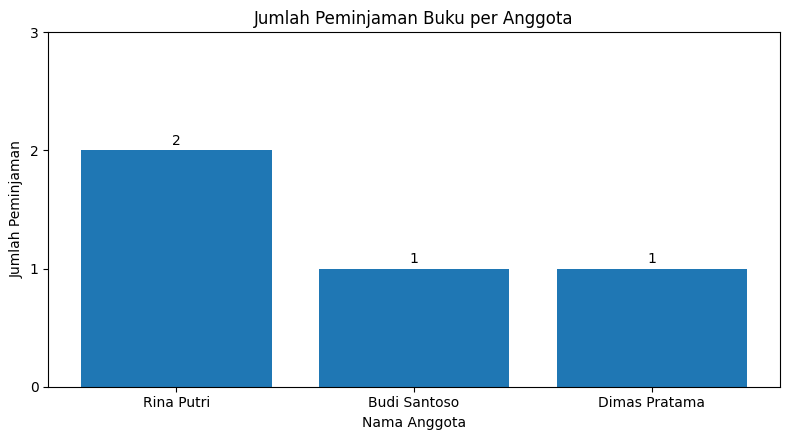

In [21]:
plt.figure(figsize=(8, 4.5))
bars = plt.bar(df_jumlah['nama_anggota'], df_jumlah['jumlah_peminjaman'])

plt.title('Jumlah Peminjaman Buku per Anggota')
plt.xlabel('Nama Anggota')
plt.ylabel('Jumlah Peminjaman')
plt.yticks(range(0, int(df_jumlah['jumlah_peminjaman'].max()) + 2))

for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
             str(int(bar.get_height())), ha='center')

plt.tight_layout()
plt.show()

**Kesimpulan singkat:** Rina Putri melakukan peminjaman paling banyak (2 buku). Dari 4 transaksi, 3 sudah dikembalikan dan 1 belum dikembalikan. Rata-rata durasi untuk peminjaman yang sudah selesai sekitar 8,33 hari.

In [22]:
conn.close()
print('Koneksi database ditutup.')

Koneksi database ditutup.
